Logistic Regression on predicting postive/ negative of women's clothing review from e-commerce website 


In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [4]:
df=pd.read_csv('D:/Courses/Certified AI-ML/Datasets/womens_clothing_ecommerce_reviews.csv')

print(df.head())

print(df.isnull().sum())

print(df.duplicated())

                                         Review Text  sentiment
0  Absolutely wonderful - silky and sexy and comf...          1
1  Love this dress!  it's sooo pretty.  i happene...          1
2  I love, love, love this jumpsuit. it's fun, fl...          1
3  This shirt is very flattering to all due to th...          1
4  I love tracy reese dresses, but this one is no...         -1
Review Text    0
sentiment      0
dtype: int64
0        False
1        False
2        False
3        False
4        False
         ...  
19813    False
19814    False
19815    False
19816    False
19817    False
Length: 19818, dtype: bool


Find the dataset details (Missing values , Duplicate Values,class count)

In [5]:
print("Dtypes:\n",df.dtypes)
print("\nMissing values:\n",df.isnull().sum())
print("Duplicate rows: ",int(df.duplicated().sum()))
print("Empty Review Text: ",int((df["Review Text"].fillna("").str.strip() =="").sum()))
print("\nClass couts (imbalance matters for accuracy)")
print(df["sentiment"].value_counts())
print("\nClass share: ")
print(df["sentiment"].value_counts(normalize=True).round(4))
print("\nLabel values: ", sorted(df["sentiment"].unique().tolist()))

Dtypes:
 Review Text      str
sentiment      int64
dtype: object

Missing values:
 Review Text    0
sentiment      0
dtype: int64
Duplicate rows:  7
Empty Review Text:  0

Class couts (imbalance matters for accuracy)
sentiment
 1    17448
-1     2370
Name: count, dtype: int64

Class share: 
sentiment
 1    0.8804
-1    0.1196
Name: proportion, dtype: float64

Label values:  [-1, 1]


Drop duplicate values

In [6]:
n_before=len(df)
df=df.drop_duplicates().reset_index(drop=True)
print(f'Dropped {n_before-len(df)} Duplicate rows.Remaining:{len(df)}')

Dropped 7 Duplicate rows.Remaining:19811


Split the dataset into train and test data

In [7]:
x=df["Review Text"]
y=df["sentiment"]

x_train,x_test,y_train,y_test=train_test_split(
   x,y,test_size=0.2,random_state=42,stratify=y)

print("Train Size:",len(x_train), "Test Size:",len(x_test))

Train Size: 15848 Test Size: 3963


Feature Engineering 

In this we want to crate vocabuary from (unique features)
for example- In this noraml regression example in morning session we get predications only from "Awesome" and "Aweful" words. 

Normally that is not inough for real review dataset.The dataset have over 15000 reviews.and unique words can be over 10k .
therfore we need to crate vocabuary from the dataset.

for that we use vectorize .fit transform feature.

In [8]:
print("\nConverting text to numerical features using Bag-of-words..")

vectozier=CountVectorizer(stop_words="english")

x_train_bow=vectozier.fit_transform(x_train)

print(f'X_train_bow Shapes:\n{x_train_bow.shape}')





Converting text to numerical features using Bag-of-words..
X_train_bow Shapes:
(15848, 11862)


According to this we create 11862 word unique values from the review of dataset.The unique values added to numerical matrix


In [9]:
print(f'Unique words( features):{vectozier.get_feature_names_out()}')

print(f'X_train_bow:\n{x_train_bow}')


Unique words( features):['00' '000' '00p' ... 'zooming' 'zuma' 'ã¼ber']
X_train_bow:
<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 373248 stored elements and shape (15848, 11862)>
  Coords	Values
  (0, 940)	1
  (0, 8751)	1
  (0, 10636)	1
  (0, 1142)	1
  (0, 9405)	1
  (0, 5853)	1
  (0, 9853)	1
  (0, 2290)	1
  (0, 3346)	1
  (0, 5791)	1
  (0, 4676)	1
  (0, 5286)	1
  (0, 5312)	1
  (0, 7341)	1
  (0, 6038)	2
  (0, 2039)	1
  (0, 9043)	1
  (0, 11213)	1
  (0, 8603)	1
  (0, 6863)	1
  (0, 6175)	1
  (0, 4178)	1
  (0, 7608)	1
  (0, 9475)	2
  (0, 11368)	1
  :	:
  (15846, 1672)	1
  (15847, 9405)	1
  (15847, 11462)	1
  (15847, 1246)	1
  (15847, 11505)	1
  (15847, 8151)	1
  (15847, 2319)	2
  (15847, 3992)	1
  (15847, 4762)	2
  (15847, 8826)	1
  (15847, 5856)	1
  (15847, 7641)	1
  (15847, 9794)	1
  (15847, 5599)	1
  (15847, 6020)	1
  (15847, 5906)	1
  (15847, 3402)	1
  (15847, 572)	1
  (15847, 2913)	2
  (15847, 10343)	1
  (15847, 11411)	1
  (15847, 2578)	1
  (15847, 7839)	1
  (15847, 8952)

In this we use different type of transform for test dataset. In train dataset we use fit_transform, but in this we use transform only . 
If we use fit transform for both seperately we create 2 differnt vocabuary. but in this we should use same feature sets.

for that we use exact same vocabuary which create in train set .\

therefore we use fit_transform for train dataset and transform for test dataset


In [10]:
x_test_bow=vectozier.transform(x_test)

print("Test successfully converted to feature vectors")

Test successfully converted to feature vectors


Hypher Parameters
in this we use max_iter and solver like hyper paramater.
Hyper parameter means the variables we ussd in model traning ( withou model weight)

The one of main task of ML engineer is the this hyper paramter tune to because sometime of we add it to large value we can get model overfitted



In [11]:
model=LogisticRegression(max_iter=1000,solver='saga',random_state=42)

model.fit(x_train_bow,y_train)

print("Model trainnig complete")

Model trainnig complete


max_iteation is used to how much shoudl iterate the dataste in modle traninig
the solver is optimization algorithm 

Model Evaluation

Accuarcy= num of accurate prediction/Total of predictions

In [12]:
from sklearn.metrics import accuracy_score


print("\nEvaluating model performance in the test set...")

y_test_pred=model.predict(x_test_bow)
y_train_pred=model.predict(x_train_bow)

accuracy=accuracy_score(y_train,y_train_pred)
print(f"model Accuarcy(Train):{accuracy:.4f}({accuracy:.2f}) ")

accuracy=accuracy_score(y_test,y_test_pred)
print(f"model Accuarcy(Test):{accuracy:.4f}({accuracy:.2f}) ")


Evaluating model performance in the test set...
model Accuarcy(Train):0.9784(0.98) 
model Accuarcy(Test):0.9286(0.93) 


In [13]:
print(classification_report(y_train,y_train_pred))
print ("-"*50)
print(classification_report(y_test,y_test_pred))


              precision    recall  f1-score   support

          -1       0.95      0.86      0.91      1895
           1       0.98      0.99      0.99     13953

    accuracy                           0.98     15848
   macro avg       0.97      0.93      0.95     15848
weighted avg       0.98      0.98      0.98     15848

--------------------------------------------------
              precision    recall  f1-score   support

          -1       0.75      0.61      0.67       474
           1       0.95      0.97      0.96      3489

    accuracy                           0.93      3963
   macro avg       0.85      0.79      0.82      3963
weighted avg       0.92      0.93      0.93      3963



In [14]:
print("Confustion Matrix:")
print(confusion_matrix(y_test,y_test_pred))

Confustion Matrix:
[[ 288  186]
 [  97 3392]]


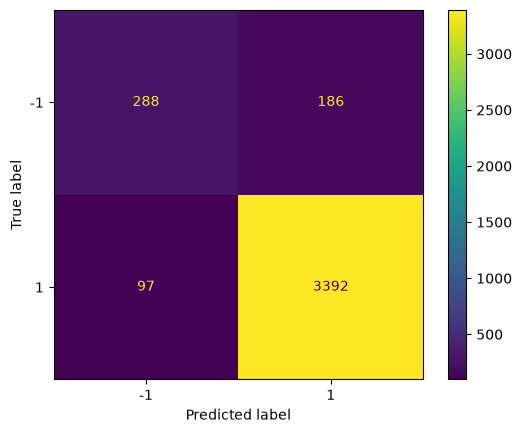

In [15]:
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred)

Add a new reviews and check the prediction

In [16]:
new_reviews = [
    "This dress is absolutely beautiful and fits perfectly!",
    "The material felt cheap and it was not what I expected.",
    "It's an okay product, not great but not terrible either.",
    "I am so disappointed with this purchase, I will be returning it.",
    "I want to buy this again and again!",
]


In [17]:
new_reviews_bow = vectozier.transform(new_reviews)
print("new_reviews_bow shape:", new_reviews_bow.shape)

new_predictions = model.predict(new_reviews_bow)

print(type(new_predictions))
print(new_predictions)


for i in range(len(new_reviews)):
    print(f"Review: {new_reviews[i]}")
    print(f"Predicted Sentiment: {new_predictions[i]}\n")

new_reviews_bow shape: (5, 11862)
<class 'numpy.ndarray'>
[ 1 -1 -1 -1  1]
Review: This dress is absolutely beautiful and fits perfectly!
Predicted Sentiment: 1

Review: The material felt cheap and it was not what I expected.
Predicted Sentiment: -1

Review: It's an okay product, not great but not terrible either.
Predicted Sentiment: -1

Review: I am so disappointed with this purchase, I will be returning it.
Predicted Sentiment: -1

Review: I want to buy this again and again!
Predicted Sentiment: 1

